In [76]:
import cv2
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from typing import List, Dict, Optional

# 2.2 Odszumianie

In [ ]:
BASE_DIR = Path("data")
RESULTS_DIR = Path("results/noisy")
GT_DIR = BASE_DIR / "processed" / "valid_256"

FOLDERS_TO_DISPLAY: list[list[Path]] = [
    [
        GT_DIR,
        BASE_DIR / "noisy" / "valid_noisy_001",
        BASE_DIR / "noisy" / "bilateral_001",
        BASE_DIR / "noisy" / "nafnet_001",
    ],
    [
        GT_DIR,
        BASE_DIR / "noisy" / "valid_noisy_003",
        BASE_DIR / "noisy" / "bilateral_003",
        BASE_DIR / "noisy" / "nafnet_003",
    ],
]

### Tabela z wynikami

In [78]:
metrics_dfs: dict[str, pd.DataFrame] = {}
summary_data: list[dict[str, str]] = []

if not RESULTS_DIR.exists():
    print(f"Results directory not found: {RESULTS_DIR}")
else:
    for csv_path in sorted(RESULTS_DIR.glob("*.csv")):
        method_name = csv_path.stem
        df = pd.read_csv(csv_path)
        metrics_dfs[method_name] = df

        summary_data.append({
            "Metoda": method_name,
            "PSNR": f"{df['PSNR'].mean():.2f}",
            "SSIM": f"{df['SSIM'].mean():.4f}",
            "LPIPS": f"{df['LPIPS'].mean():.4f}",
        })

    if summary_data:
        df_summary = pd.DataFrame(summary_data)
        print("Wyniki ewaluacji dla zadania 2.2 odszumiania")
        display(df_summary)
    else:
        print("No CSV files found in the results directory.")

Wyniki ewaluacji dla zadania 2.2 odszumiania


,Metoda,PSNR,SSIM,LPIPS
0,bilateral_001,31.95,0.9309,0.0452
1,bilateral_003,25.48,0.7694,0.1687
2,nafnet_001,42.08,0.9883,0.0031
3,nafnet_0012,42.08,0.9883,0.0031


## Pojedyncze próbki

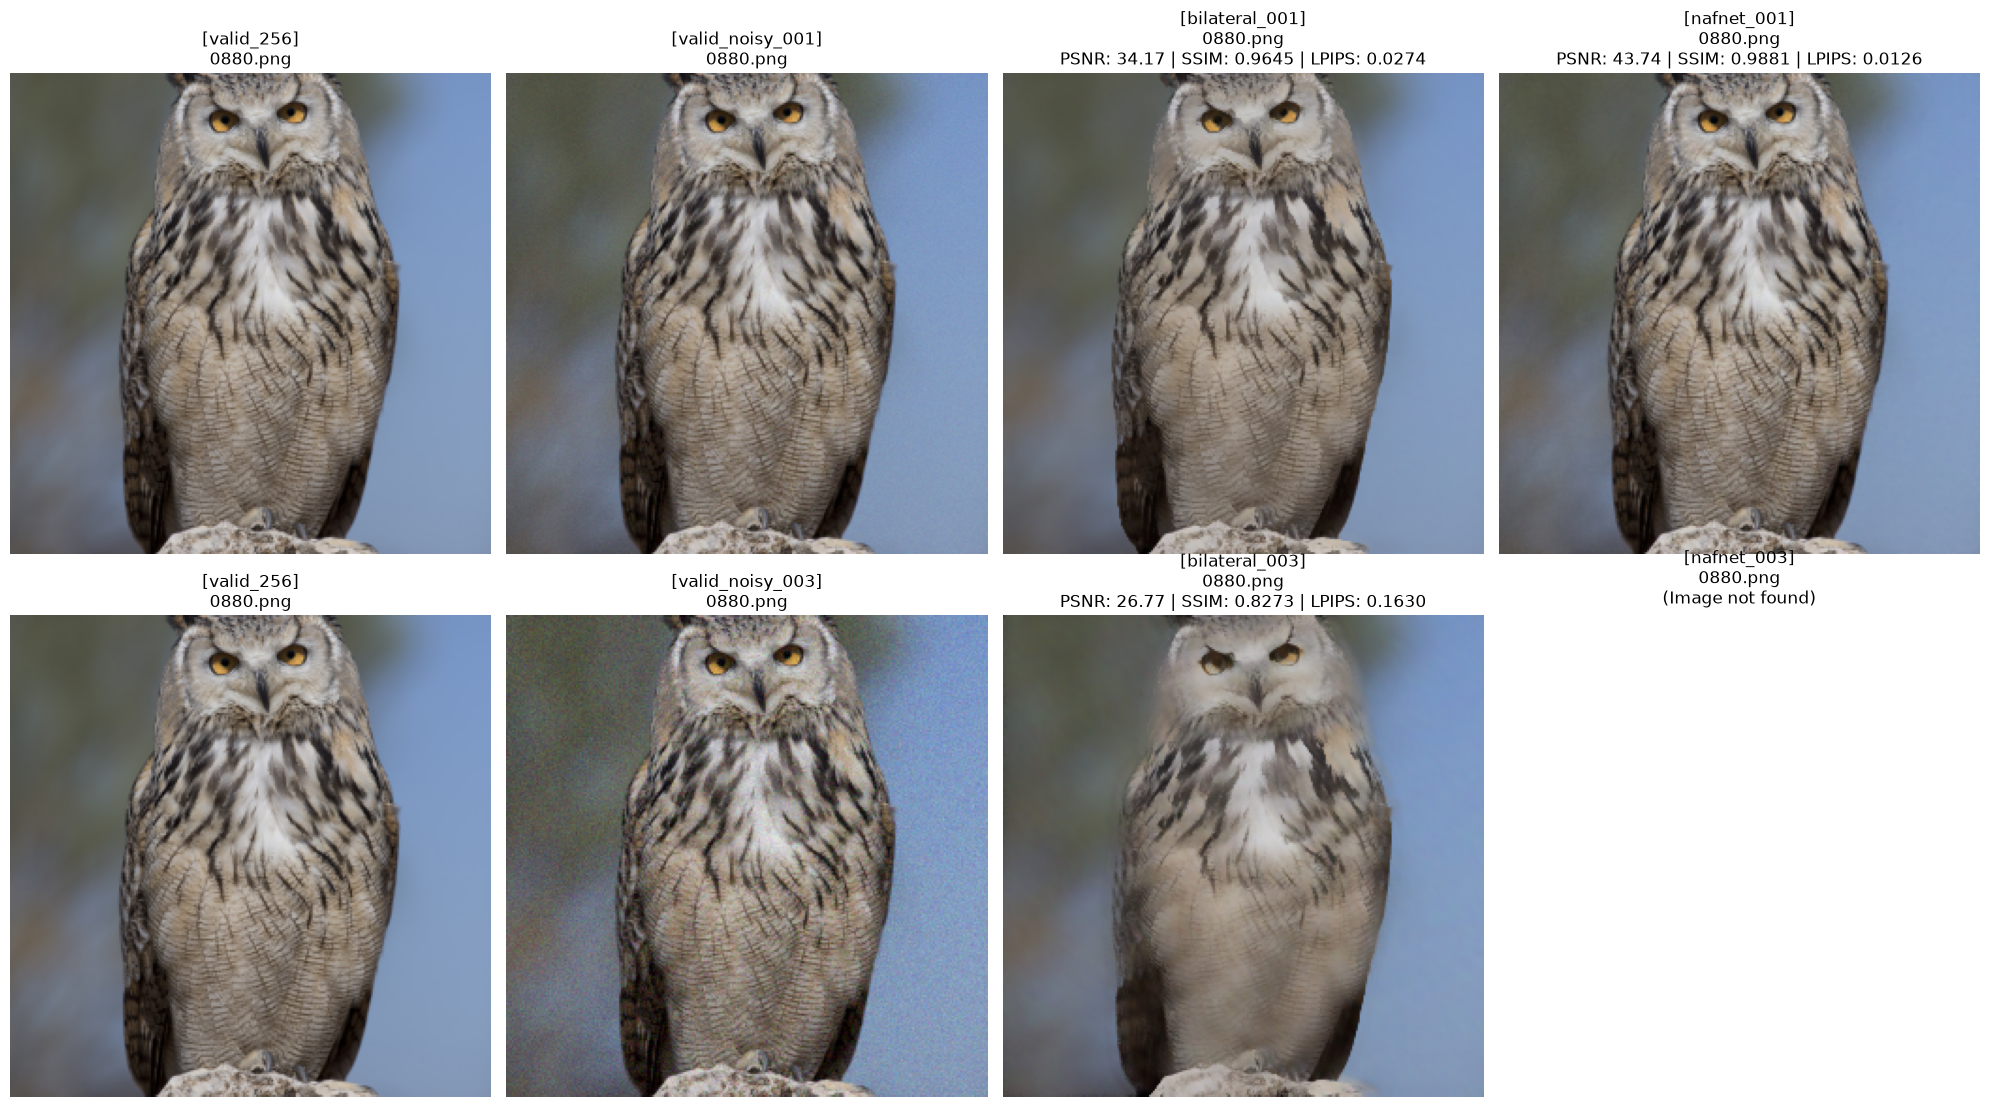

In [79]:
def load_rgb_image(path: Path) -> np.ndarray | None:
    """Loads an image from disk and converts it to RGB, returning None if not found."""
    if not path.exists():
        return None
    img_bgr = cv2.imread(str(path))
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB) if img_bgr is not None else None


all_images = list(GT_DIR.glob("*.png")) + list(GT_DIR.glob("*.jpg"))

if not all_images:
    print("No images found in the Ground Truth directory!")
else:
    random_image_path = random.choice(all_images)
    image_name = random_image_path.name

    num_rows = len(FOLDERS_TO_DISPLAY)
    num_cols = max(len(row) for row in FOLDERS_TO_DISPLAY)

    fig, axes = plt.subplots(
        num_rows,
        num_cols,
        figsize=(5 * num_cols, 5.5 * num_rows),
        squeeze=False,
    )

    for row_idx, folder_row in enumerate(FOLDERS_TO_DISPLAY):
        for col_idx, folder_path in enumerate(folder_row):
            ax = axes[row_idx, col_idx]
            label = folder_path.name
            img_file = folder_path / image_name

            img = load_rgb_image(img_file)

            if img is None:
                ax.set_title(f"[{label}]\n{image_name}\n(Image not found)", fontsize=12)
                ax.axis("off")
                continue

            metrics_text = ""
            if label in metrics_dfs:
                df = metrics_dfs[label]
                row = df[df["image_name"] == image_name]

                if not row.empty:
                    psnr = row.iloc[0]["PSNR"]
                    ssim = row.iloc[0]["SSIM"]
                    lpips = row.iloc[0]["LPIPS"]
                    metrics_text = f"\nPSNR: {psnr:.2f} | SSIM: {ssim:.4f} | LPIPS: {lpips:.4f}"

            ax.imshow(img)
            ax.set_title(f"[{label}]\n{image_name}{metrics_text}", fontsize=12)
            ax.axis("off")

    plt.tight_layout()
    plt.show()